In [2]:
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual styles
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Connect to database and load data
conn = sqlite3.connect("../data/echallan_db.sqlite")
df = pd.read_sql_query("SELECT * FROM echallan_records", conn)
conn.close()

# Convert Date to datetime if not already
df["Date"] = pd.to_datetime(df["Date"])

print(f"Loaded {len(df)} records from database.")
df.head()

Loaded 10000 records from database.


,Challan_ID,Date,Year,Month,Day_of_Week,City,Province,Violation_Type,Vehicle_Type,Enforcement_Method,Fine_Amount_PKR,Payment_Status,Amount_Collected_PKR,Outstanding_Amount_PKR
0,PK-10000,2026-05-13,2026,May,Wednesday,Karachi,Sindh,Mobile Phone Use,Bus,Police Officer,1732.0,Paid,1732.0,0.0
1,PK-10001,2020-01-01,2020,January,Wednesday,Rawalpindi,Punjab,Mobile Phone Use,Car,Speed Gun,1732.0,Paid,1732.0,0.0
2,PK-10002,2024-05-06,2024,May,Monday,Faisalabad,Punjab,Speeding,Bus,Camera,1904.0,Paid,1904.0,0.0
3,PK-10003,2019-04-22,2019,April,Monday,Rawalpindi,Punjab,Seatbelt Violation,Bus,Police Officer,1000.0,Paid,1000.0,0.0
4,PK-10004,2023-09-26,2023,September,Tuesday,Lahore,Punjab,Seatbelt Violation,Rickshaw,Speed Gun,1000.0,Paid,1000.0,0.0


=== City Revenue & Recovery Rates Summary ===
      City  Total_Challans  Total_Fine_Assessed_PKR  Total_Revenue_Collected_PKR  Avg_Revenue_Per_Challan_PKR  Recovery_Rate_%
   Karachi            1699                3575986.0                    2504561.0                  1474.138317        70.038333
 Hyderabad            1675                3387229.0                    2444993.0                  1459.697313        72.182690
    Lahore            1674                3413104.0                    2380803.0                  1422.224014        69.754775
Rawalpindi            1670                3329112.0                    2337192.0                  1399.516168        70.204667
  Peshawar            1646                3315888.0                    2330257.0                  1415.708991        70.275504
Faisalabad            1636                3304321.0                    2305507.0                  1409.234108        69.772489


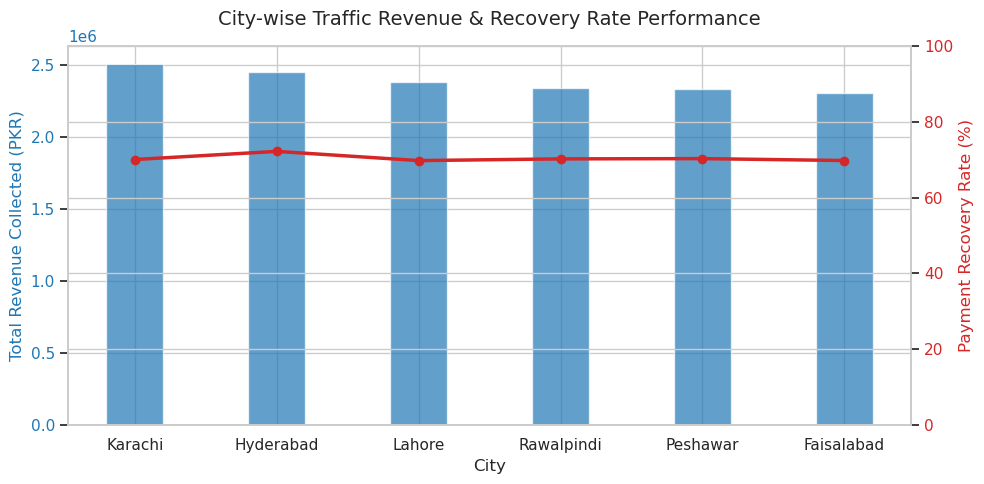

In [2]:
# 1. Group by City and aggregate financial metrics
city_summary = (
    df.groupby("City")
    .agg(
        Total_Challans=("Challan_ID", "count"),
        Total_Fine_Assessed_PKR=("Fine_Amount_PKR", "sum"),
        Total_Revenue_Collected_PKR=("Amount_Collected_PKR", "sum"),
        Avg_Revenue_Per_Challan_PKR=("Amount_Collected_PKR", "mean"),
    )
    .reset_index()
)

# 2. Calculate Payment Recovery Rate Percentage
city_summary["Recovery_Rate_%"] = (
    city_summary["Total_Revenue_Collected_PKR"]
    / city_summary["Total_Fine_Assessed_PKR"]
) * 100

# Sort by Total Revenue Collected descending
city_summary = city_summary.sort_values(
    by="Total_Revenue_Collected_PKR", ascending=False
)

print("=== City Revenue & Recovery Rates Summary ===")
print(city_summary.to_string(index=False))

# 3. Visualization: Bar Plot of Average Revenue vs. Recovery Rate
fig, ax1 = plt.subplots(figsize=(10, 5))

# Primary Bar Chart: Total Revenue Collected
color = "tab:blue"
ax1.set_xlabel("City", fontsize=12)
ax1.set_ylabel(
    "Total Revenue Collected (PKR)", color=color, fontsize=12
)
bars = ax1.bar(
    city_summary["City"],
    city_summary["Total_Revenue_Collected_PKR"],
    color=color,
    alpha=0.7,
    width=0.4,
)
ax1.tick_params(axis="y", labelcolor=color)

# Secondary Line Chart: Recovery Rate %
ax2 = ax1.twinx()
color = "tab:red"
ax2.set_ylabel("Payment Recovery Rate (%)", color=color, fontsize=12)
line = ax2.plot(
    city_summary["City"],
    city_summary["Recovery_Rate_%"],
    color=color,
    marker="o",
    linewidth=2.5,
)
ax2.tick_params(axis="y", labelcolor=color)
ax2.set_ylim(0, 100)

plt.title(
    "City-wise Traffic Revenue & Recovery Rate Performance",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()


=== Enforcement Method Efficiency Summary ===
Enforcement_Method  Total_Challans  Total_Assessed_PKR  Total_Collected_PKR  Avg_Fine_PKR  Recovery_Rate_%
            Camera            3345           6776796.0            4718611.0   2025.947982        69.628937
    Police Officer            3245           6551902.0            4689937.0   2019.076117        71.581306
         Speed Gun            3410           6996942.0            4894765.0   2051.889150        69.955775


C:\Users\hnase\AppData\Local\Temp\ipykernel_18800\3404951186.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\hnase\AppData\Local\Temp\ipykernel_18800\3404951186.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


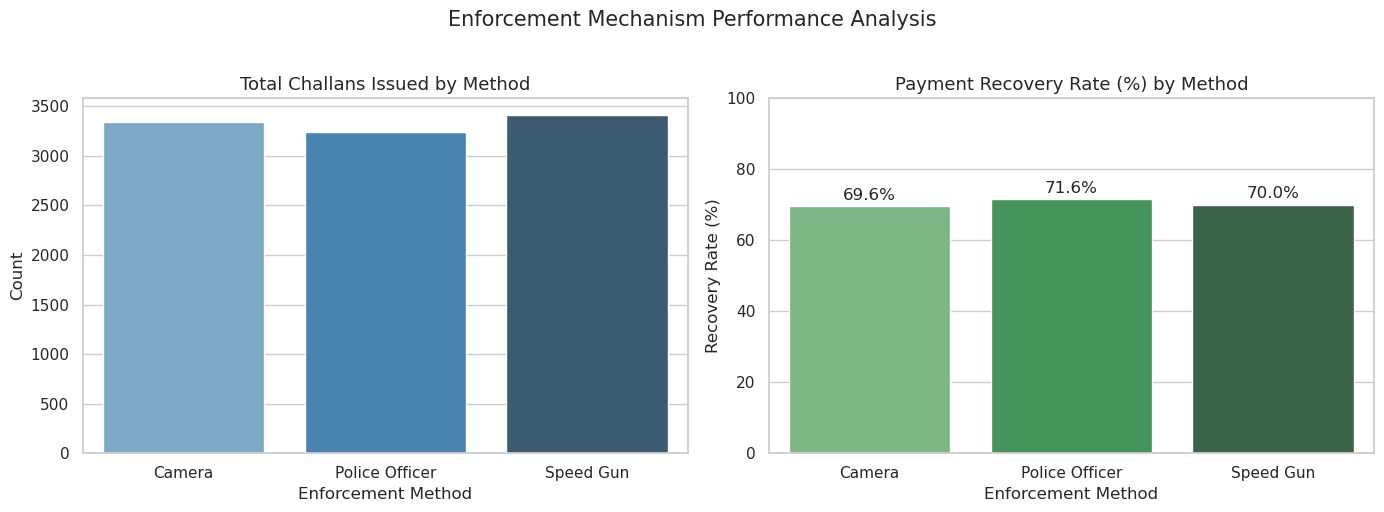

In [5]:
# -------------------------------------------------------------
# OBJECTIVE 2: Enforcement Method Efficiency
# -------------------------------------------------------------
enforcement_summary = (
    df.groupby("Enforcement_Method")
    .agg(
        Total_Challans=("Challan_ID", "count"),
        Total_Assessed_PKR=("Fine_Amount_PKR", "sum"),
        Total_Collected_PKR=("Amount_Collected_PKR", "sum"),
        Avg_Fine_PKR=("Fine_Amount_PKR", "mean"),
    )
    .reset_index()
)

# Calculate Payment Recovery Rate %
enforcement_summary["Recovery_Rate_%"] = (
    enforcement_summary["Total_Collected_PKR"]
    / enforcement_summary["Total_Assessed_PKR"]
) * 100

print("\n=== Enforcement Method Efficiency Summary ===")
print(enforcement_summary.to_string(index=False))

# Visualization: Side-by-Side Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Total Challans issued by Enforcement Method
sns.barplot(
    data=enforcement_summary,
    x="Enforcement_Method",
    y="Total_Challans",
    ax=ax1,
    palette="Blues_d",
)
ax1.set_title("Total Challans Issued by Method", fontsize=13)
ax1.set_xlabel("Enforcement Method")
ax1.set_ylabel("Count")

# Subplot 2: Payment Recovery Rate % by Enforcement Method
sns.barplot(
    data=enforcement_summary,
    x="Enforcement_Method",
    y="Recovery_Rate_%",
    ax=ax2,
    palette="Greens_d",
)
ax2.set_title("Payment Recovery Rate (%) by Method", fontsize=13)
ax2.set_xlabel("Enforcement Method")
ax2.set_ylabel("Recovery Rate (%)")
ax2.set_ylim(0, 100)

# Add value labels on top of bars
for p in ax2.patches:
    ax2.annotate(
        f"{p.get_height():.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 8),
        textcoords="offset points",
    )

plt.suptitle("Enforcement Mechanism Performance Analysis", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [7]:
matrix = pd.crosstab(
    df["Vehicle_Type"], df["Violation_Type"],values=df["Fine_Amount_PKR"], aggfunc="sum", margins=True
)

In [8]:
print(matrix)

Violation_Type    Mobile Phone Use  No Helmet  Reckless Driving  \
Vehicle_Type                                                      
Bus                       559436.0   400654.0         1626468.0   
Car                       606200.0   444898.0         1459902.0   
Commercial Truck          635644.0   414173.0         1646064.0   
Motorcycle                555972.0   436295.0         1646064.0   
Rickshaw                  585416.0   394509.0         1601973.0   
All                      2942668.0  2090529.0         7980471.0   

Violation_Type    Seatbelt Violation  Signal Violation   Speeding         All  
Vehicle_Type                                                                   
Bus                         312000.0          568500.0   626416.0   4093474.0  
Car                         326000.0          481500.0   670208.0   3988708.0  
Commercial Truck            313000.0          480000.0   590240.0   4079121.0  
Motorcycle                  348000.0          447000.0   681632

In [13]:
matrix_pct = (pd.crosstab(df["Vehicle_Type"],df["Violation_Type"],normalize="index")*100)

In [14]:
print(matrix_pct)

Violation_Type    Mobile Phone Use  No Helmet  Reckless Driving  \
Vehicle_Type                                                      
Bus                      16.141929  16.291854         16.591704   
Car                      17.421603  18.018915         14.833250   
Commercial Truck         18.507312  16.994453         16.944024   
Motorcycle               15.922619  17.609127         16.666667   
Rickshaw                 16.976394  16.122551         16.423908   

Violation_Type    Seatbelt Violation  Signal Violation   Speeding  
Vehicle_Type                                                       
Bus                        15.592204         18.940530  16.441779  
Car                        16.226979         15.978099  17.521155  
Commercial Truck           15.784165         16.137166  15.632879  
Motorcycle                 17.261905         14.781746  17.757937  
Rickshaw                   17.980914         15.218483  17.277750  


NameError: name '__file__' is not defined


=== Strategic Policy Matrix (Percentages %) ===
Violation_Type    Mobile Phone Use  No Helmet  Reckless Driving  \
Vehicle_Type                                                      
Bus                          16.14      16.29             16.59   
Car                          17.42      18.02             14.83   
Commercial Truck             18.51      16.99             16.94   
Motorcycle                   15.92      17.61             16.67   
Rickshaw                     16.98      16.12             16.42   

Violation_Type    Seatbelt Violation  Signal Violation  Speeding  
Vehicle_Type                                                      
Bus                            15.59             18.94     16.44  
Car                            16.23             15.98     17.52  
Commercial Truck               15.78             16.14     15.63  
Motorcycle                     17.26             14.78     17.76  
Rickshaw                       17.98             15.22     17.28  


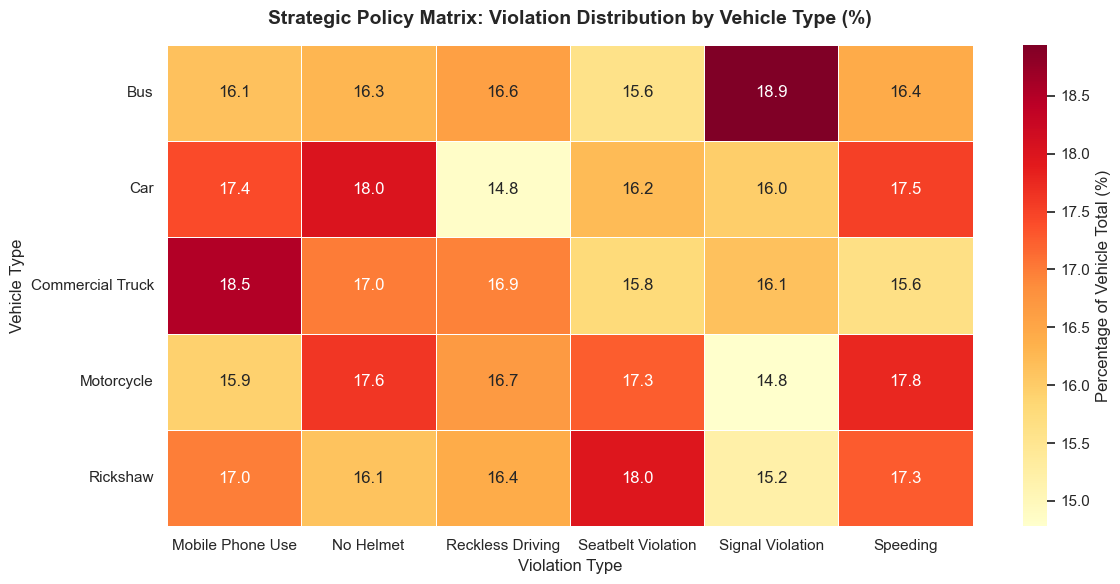

In [16]:
# -------------------------------------------------------------
# OBJECTIVE 4: Strategic Policy Matrix
# -------------------------------------------------------------
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Compute Row Percentages (Proportion of violations per vehicle type)
matrix_pct = (
    pd.crosstab(df["Vehicle_Type"], df["Violation_Type"], normalize="index")
    * 100
)

print("\n=== Strategic Policy Matrix (Percentages %) ===")
print(matrix_pct.round(2))

# Visualization: Annotated Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(
    matrix_pct,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Percentage of Vehicle Total (%)"},
    linewidths=0.5,
)

plt.title(
    "Strategic Policy Matrix: Violation Distribution by Vehicle Type (%)",
    fontsize=14,
    pad=15,
    fontweight="bold",
)
plt.xlabel("Violation Type", fontsize=12)
plt.ylabel("Vehicle Type", fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
provincial_summary = (
    df.groupby(["Province", "Payment_Status"])
    .agg(
        Total_Challans=("Challan_ID", "count"),
        Total_Fine_Assessed_PKR=("Fine_Amount_PKR", "sum"),
        Total_Amount_Collected_PKR=("Amount_Collected_PKR", "sum"),
    )
    .reset_index()
)

In [20]:
print(provincial_summary.to_string(index=False))

Province Payment_Status  Total_Challans  Total_Fine_Assessed_PKR  Total_Amount_Collected_PKR
     KPK           Paid            1158                2330257.0                   2330257.0
     KPK         Unpaid             488                 985631.0                         0.0
  Punjab           Paid            3470                7023502.0                   7023502.0
  Punjab         Unpaid            1510                3023035.0                         0.0
   Sindh           Paid            2400                4949554.0                   4949554.0
   Sindh         Unpaid             974                2013661.0                         0.0


C:\Users\hnase\AppData\Local\Temp\ipykernel_22400\2806734509.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


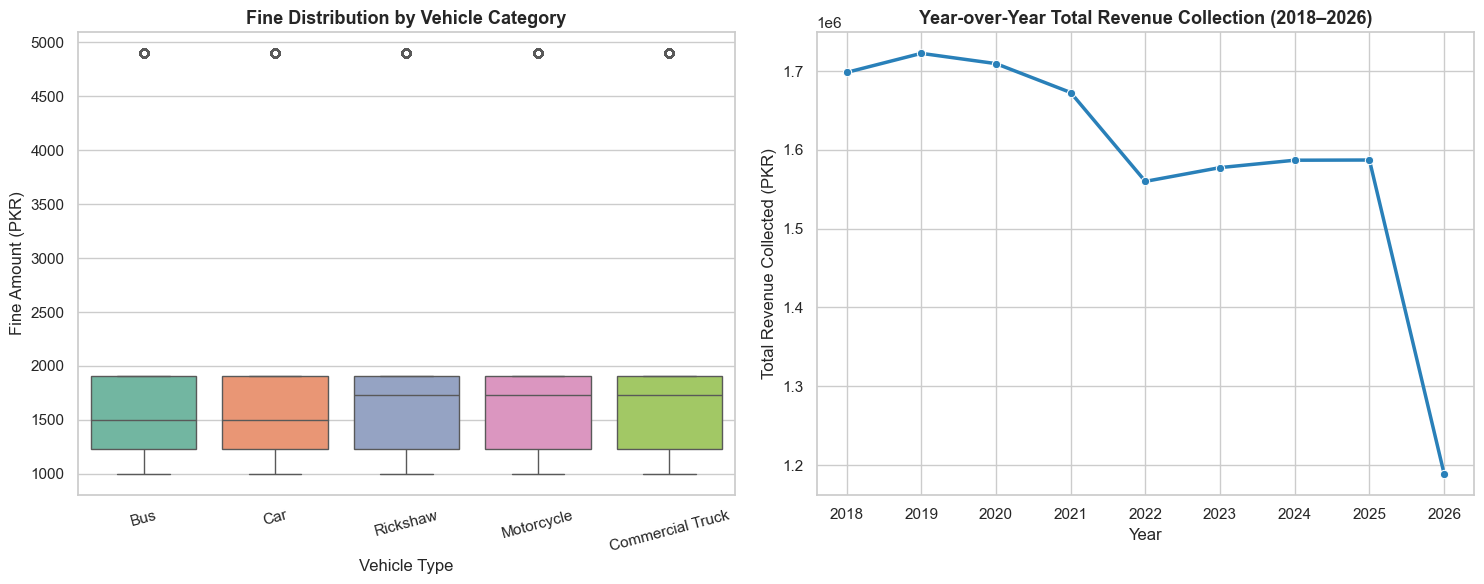

In [21]:
# -------------------------------------------------------------
# OBJECTIVE 6 & 7: Fine Distributions & Yearly Trends
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Fine Amount Boxplot across Vehicle Types
sns.boxplot(
    data=df,
    x="Vehicle_Type",
    y="Fine_Amount_PKR",
    ax=ax1,
    palette="Set2",
)
ax1.set_title(
    "Fine Distribution by Vehicle Category", fontsize=13, fontweight="bold"
)
ax1.set_xlabel("Vehicle Type")
ax1.set_ylabel("Fine Amount (PKR)")
ax1.tick_params(axis="x", rotation=15)

# Subplot 2: Year-over-Year Revenue Growth Trend
yearly_trend = (
    df.groupby("Year")["Amount_Collected_PKR"].sum().reset_index()
)
sns.lineplot(
    data=yearly_trend,
    x="Year",
    y="Amount_Collected_PKR",
    marker="o",
    color="#2980b9",
    linewidth=2.5,
    ax=ax2,
)
ax2.set_title(
    "Year-over-Year Total Revenue Collection (2018–2026)",
    fontsize=13,
    fontweight="bold",
)
ax2.set_xlabel("Year")
ax2.set_ylabel("Total Revenue Collected (PKR)")

plt.tight_layout()
plt.show()